# Retail Demand Forecasting
Revised from Nivedha Sivakumar's saved retail capstone, focusing on interpretable ML rather than its legacy ARIMA and neural-network experiments. The original version remains in Git history.

## Goal and evaluation design
Forecast daily sales using known calendar, promotion, holiday, and store-opening features. Customer counts are excluded because they may be observed only after trading. Future promotion and opening schedules are assumed available. Date-only features avoid target lags requiring future actual sales.

A fixed, evenly spaced cohort of 30 store IDs is selected from training metadata to keep this example practical to reproduce. This is not a full-chain benchmark; set `STORE_LIMIT = None` to use all stores. Store selection does not use sales or test performance. Compare a seasonal-naive baseline with linear regression, a decision tree, and a random forest using expanding training windows and April, May, and June 2015 validation months. Choose by mean validation MAE, refit through June, then evaluate once on the separate July labels.


## Executed results

Expanding-window validation selected linear regression. The July 2015 holdout contains 930 store-days across 30 preselected stores. Holdout MAE: 791.19; RMSE: 1113.01 sales units; WAPE: 12.57%. Seasonal-naive WAPE: 24.35%. These are historical cohort results, not full-chain or current performance.

In [1]:
get_ipython().run_line_magic('matplotlib', 'inline')
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.figsize': (10, 5), 'font.size': 11})
SEED = 42

STORE_LIMIT = 30


## Validate training inputs and choose the fixed store cohort

Training rows: 26410 Stores: 30
Training period: 2013-01-01 through 2015-06-30


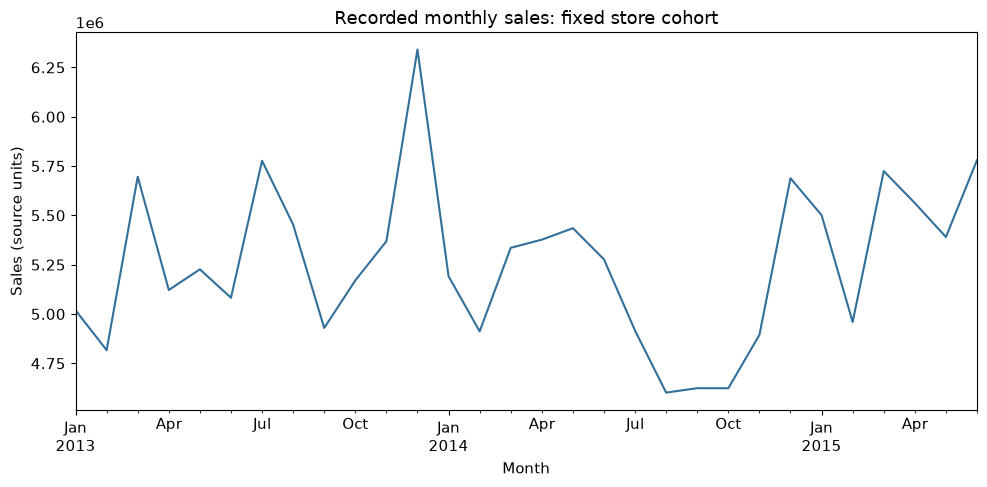

In [2]:
train = pd.read_csv(Path('data') / 'train_data.csv', dtype={'StateHoliday':str}, low_memory=False)
train['Date'] = pd.to_datetime(train['Date'], format='%Y-%m-%d', errors='raise')
keys = ['Store','Date']
assert not train.duplicated(keys).any(), 'Duplicate store/date keys'
assert not train.isna().any().any(), 'Missing training values require review'
assert train['Sales'].ge(0).all()
assert train['Date'].max() < pd.Timestamp('2015-07-01')
stores = np.sort(train['Store'].unique())
if STORE_LIMIT is not None:
    stores = stores[np.linspace(0, len(stores)-1, min(STORE_LIMIT,len(stores)), dtype=int)]
train = train.loc[train['Store'].isin(stores)].sort_values(keys).reset_index(drop=True)
print('Training rows:', len(train), 'Stores:', len(stores))
print('Training period:', train['Date'].min().date(), 'through', train['Date'].max().date())
monthly = train.groupby(train['Date'].dt.to_period('M'))['Sales'].sum()
monthly.index = monthly.index.to_timestamp()
monthly.plot(color='#326f9a')
plt.title('Recorded monthly sales: fixed store cohort');plt.ylabel('Sales (source units)');plt.xlabel('Month')
plt.tight_layout();plt.show()


## Build training-fitted pipelines and a seasonal baseline

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
def features(frame):
    x = frame[['Store','Open','Promo','StateHoliday','SchoolHoliday']].copy()
    x['Store'] = x['Store'].astype(str)
    x['Weekday'] = frame['Date'].dt.dayofweek.astype(str)
    x['Month'] = frame['Date'].dt.month.astype(str)
    x['Day'] = frame['Date'].dt.day
    x['Trend'] = (frame['Date'] - pd.Timestamp('2013-01-01')).dt.days
    return x
def pipeline(name):
    category = ['Store','StateHoliday','Weekday','Month']
    numeric = ['Open','Promo','SchoolHoliday','Day','Trend']
    pre = ColumnTransformer([('category',OneHotEncoder(handle_unknown='ignore',sparse_output=False),category),
                             ('numeric',StandardScaler(),numeric)])
    estimator = {'Linear regression':LinearRegression(),
                 'Decision tree':DecisionTreeRegressor(max_depth=12,min_samples_leaf=8,random_state=SEED),
                 'Random forest':RandomForestRegressor(n_estimators=60,max_depth=14,min_samples_leaf=8,random_state=SEED,n_jobs=2)}[name]
    return make_pipeline(pre, estimator)
def seasonal_naive(history, future):
    # Last observed sale for the same store and weekday; no holdout labels used.
    previous = history.assign(Weekday=history['Date'].dt.dayofweek).sort_values('Date').drop_duplicates(['Store','Weekday'],keep='last')
    lookup = previous.set_index(['Store','Weekday'])['Sales']
    index = pd.MultiIndex.from_arrays([future['Store'],future['Date'].dt.dayofweek])
    values = lookup.reindex(index).to_numpy()
    assert np.isfinite(values).all(), 'Missing seasonal history'
    return np.where(future['Open'].to_numpy()==0,0,values)
def predict(model, frame):
    return np.where(frame['Open'].to_numpy()==0,0,np.maximum(0,model.predict(features(frame))))
def metrics(actual, prediction):
    return {'MAE':float(mean_absolute_error(actual,prediction)),
            'RMSE':float(np.sqrt(mean_squared_error(actual,prediction))),
            'WAPE':float(np.abs(actual-prediction).sum()/np.abs(actual).sum())}
names = ['Seasonal naive','Linear regression','Decision tree','Random forest']


## Expanding-window validation
All stores share the same date boundaries. Model settings are fixed in advance; July labels are not used for selection.

Mean scores across three validation months:
                         MAE       RMSE    WAPE
model                                          
Linear regression   913.7628  1376.4949  0.1491
Random forest       985.3594  1435.4973  0.1607
Decision tree      1094.6452  1598.7710  0.1785
Seasonal naive     1775.7951  2860.1459  0.2873
Selected by validation MAE: Linear regression


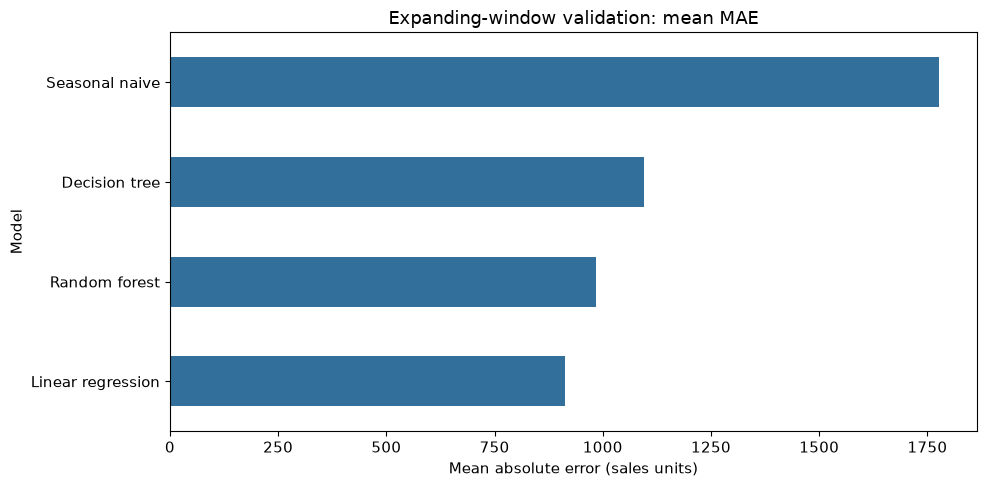

In [4]:
validation_rows = []
for start in pd.to_datetime(['2015-04-01','2015-05-01','2015-06-01']):
    end = start + pd.offsets.MonthBegin(1)
    past = train.loc[train['Date'] < start]
    validation = train.loc[train['Date'].ge(start) & train['Date'].lt(end)]
    assert past['Date'].max() < validation['Date'].min()
    for name in names:
        if name == 'Seasonal naive':
            prediction = seasonal_naive(past,validation)
        else:
            model = pipeline(name).fit(features(past),past['Sales'])
            prediction = predict(model,validation)
        validation_rows.append({'model':name,'month':str(start.date()),**metrics(validation['Sales'].to_numpy(),prediction)})
validation_scores = pd.DataFrame(validation_rows)
comparison = validation_scores.groupby('model')[['MAE','RMSE','WAPE']].mean().sort_values('MAE')
selected = comparison['MAE'].idxmin()
print('Mean scores across three validation months:')
print(comparison.round(4).to_string())
print('Selected by validation MAE:',selected)
comparison['MAE'].sort_values().plot.barh(color='#326f9a')
plt.title('Expanding-window validation: mean MAE');plt.xlabel('Mean absolute error (sales units)');plt.ylabel('Model')
plt.tight_layout();plt.show()


## One final July holdout evaluation
Join labels to features by store and date, check agreement with the supplied unlabeled test file, and retain all July days in the cohort.

July holdout rows: 930
Selected model: Linear regression
Selected model metrics: {"MAE": 791.1929811760939, "RMSE": 1113.0099264356556, "WAPE": 0.12567483983731267}
Seasonal naive metrics: {"MAE": 1532.8752688172044, "RMSE": 2276.7779208950683, "WAPE": 0.24348529180936135}


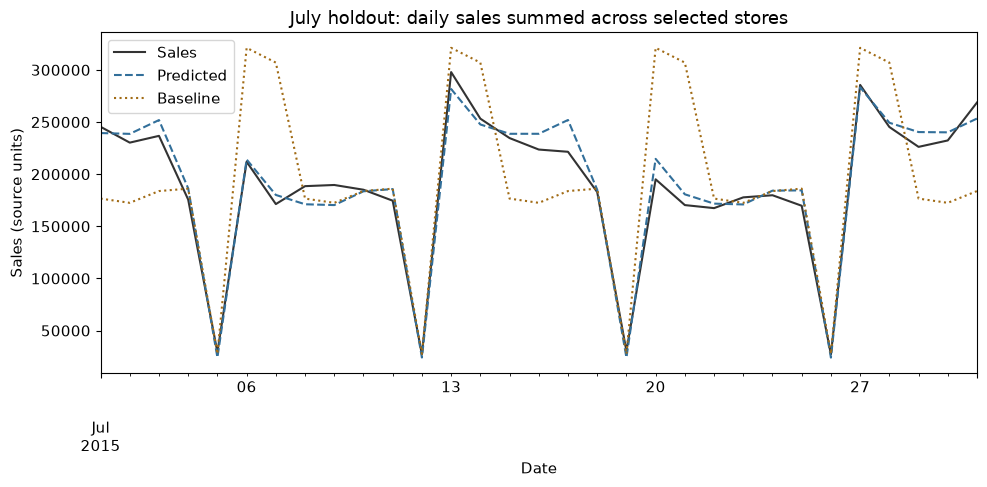

In [5]:
future = pd.read_csv(Path('data')/'test_data.csv',dtype={'StateHoliday':str},low_memory=False)
future['Date'] = pd.to_datetime(future['Date'],format='%d-%m-%Y',errors='raise')
actual = pd.read_csv(Path('data')/'test_data_hidden.csv',dtype={'StateHoliday':str},low_memory=False)
actual['Date'] = pd.to_datetime(actual['Date'],format='%Y-%m-%d',errors='raise')
assert not future.duplicated(keys).any() and not actual.duplicated(keys).any()
future = future.loc[future['Store'].isin(stores)].copy()
actual = actual.loc[actual['Store'].isin(stores)].copy()
assert set(map(tuple,future[keys].to_numpy())) == set(map(tuple,actual[keys].to_numpy()))
holdout = future.merge(actual[keys+['Sales']],on=keys,validate='one_to_one')
assert holdout['Date'].min() > train['Date'].max()
assert holdout['Date'].min()==pd.Timestamp('2015-07-01') and holdout['Date'].max()==pd.Timestamp('2015-07-31')
assert len(holdout)==len(stores)*31 and not holdout.isna().any().any()
shared = ['Store','Date','Open','Promo','StateHoliday','SchoolHoliday']
pd.testing.assert_frame_equal(future.sort_values(keys)[shared].reset_index(drop=True), actual.sort_values(keys)[shared].reset_index(drop=True))
baseline_prediction = seasonal_naive(train,holdout)
if selected=='Seasonal naive':
    prediction = baseline_prediction.copy()
else:
    final_model = pipeline(selected).fit(features(train),train['Sales'])
    prediction = predict(final_model,holdout)
final_metrics = metrics(holdout['Sales'].to_numpy(),prediction)
baseline_metrics = metrics(holdout['Sales'].to_numpy(),baseline_prediction)
print('July holdout rows:',len(holdout))
print('Selected model:',selected)
print('Selected model metrics:',json.dumps(final_metrics))
print('Seasonal naive metrics:',json.dumps(baseline_metrics))
daily = holdout.assign(Predicted=prediction,Baseline=baseline_prediction).groupby('Date')[['Sales','Predicted','Baseline']].sum()
ax=daily.plot(color=['#333333','#326f9a','#a16b15'],style=['-','--',':'])
ax.set(title='July holdout: daily sales summed across selected stores',xlabel='Date',ylabel='Sales (source units)')
plt.tight_layout();plt.show()
results = {'stores':stores.tolist(),'training_rows':len(train),'holdout_rows':len(holdout),
           'selected_model':selected,'test_period':'2015-07-01 to 2015-07-31',
           'validation_scores':validation_scores.to_dict(orient='records'),
           'holdout_metrics':final_metrics,'seasonal_naive_metrics':baseline_metrics}
Path('results.json').write_text(json.dumps(results,indent=2))


## Limits
Scores apply to this fixed store cohort and one historical month, not current performance or the whole chain. Future opening and promotion schedules are assumed known. Seasonal effects, store heterogeneity, and regime changes can reduce generalization. WAPE aggregates absolute errors across store-days and remains meaningful with zero-sales days; MAPE is intentionally avoided. No business savings or production readiness is claimed. The source and redistribution rights of the course files remain unverified.
